# Changing priors at inference time

A neural posterior estimator (NPE) is usually trained for one fixed prior or a set of priors [1, 2]. This is not always necessary. When new prior information becomes available, importance sampling can adapt its posterior samples without training a second network, as long as the old and the new prior are available in closed form. The idea is so simple and well-known, that it warrants neither a paper, nor a blog post, although we are always happy to be surprised.

This tutorial shows how to apply BayesFlow's `importance_resample` utility directly to the sample dictionary returned by a workflow.

- [1] Elsemüller, L., Olischläger, H., Schmitt, M., Bürkner, P. C., Köthe, U., & Radev, S. T. (2023). Sensitivity-aware amortized Bayesian inference. *TMLR*. [arXiv link](https://arxiv.org/abs/2310.11122) 
- [2] Huang, J. M., Schumacher, L., Stevenson, N., & Radev, S. T. (2026). CogFormer: Learn All Your Models Once. *ProbML*. [arXiv link](https://arxiv.org/abs/2603.20520) 

`importance_resample` accepts either precomputed old and new log-density arrays or callables that evaluate the sample structure, as demonstrated below.

## A noisy pulse model

We demonstrate the idea based on a simple example. At fixed times $t_1, \ldots, t_J$, we observe a Gaussian pulse:

$$
x_j \mid A, \tau \sim \mathcal{N}\!\left(
A \exp\left[-\frac{(t_j-\tau)^2}{2s^2}\right],
\sigma^2
\right).
$$

The amplitude $A$ controls the pulse height and the arrival time $\tau$ its position. The width $s=0.08$ and noise standard deviation $\sigma=0.20$ are known. We train under the broad independent prior

$$A \sim \mathcal{U}(0.5, 2.0), \qquad \tau \sim \mathcal{U}(0.2, 0.8).$$

In the implementation below, we relax the fixed-noise assumption and infer $\sigma$ jointly. Training uses $\sigma \sim \mathcal{U}(0.05, 0.50)$, while the inference-time shift uses a sharper Gamma prior (shape 100, scale 0.002) truncated to the same support.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import beta as beta_dist
from scipy.stats import gamma as gamma_dist
from scipy.stats import uniform as uniform_dist

import bayesflow as bf

In [3]:
TIMES = np.linspace(0.0, 1.0, 25)
WIDTH = 0.08
AMPLITUDE_BOUNDS = (0.5, 2.0)
ARRIVAL_BOUNDS = (0.2, 0.8)
SIGMA_BOUNDS = (0.05, 0.50)
NEW_SIGMA_SHAPE = 100.0
NEW_SIGMA_SCALE = 0.002
PARAMETER_KEYS = ("amplitude", "arrival_time", "sigma")
LABELS = ["Amplitude", "Arrival time", "Noise scale"]


def scale_from_unit_interval(unit_values, bounds):
    return bounds[0] + (bounds[1] - bounds[0]) * unit_values


def simulate_pulses(num_simulations, prior, rng=None):
    """A pulse simulator with two possible priors."""

    if rng is None:
        rng = np.random.default_rng()

    if prior == "training":
        amplitude_unit = rng.uniform(size=num_simulations)
        arrival_unit = rng.uniform(size=num_simulations)
        sigma = rng.uniform(*SIGMA_BOUNDS, size=num_simulations)
    elif prior == "new":
        amplitude_unit = rng.beta(2.0, 5.0, size=num_simulations)
        arrival_unit = rng.beta(5.0, 2.0, size=num_simulations)
        sigma_cdf_bounds = gamma_dist.cdf(
            SIGMA_BOUNDS, a=NEW_SIGMA_SHAPE, scale=NEW_SIGMA_SCALE
        )
        sigma = gamma_dist.ppf(
            rng.uniform(*sigma_cdf_bounds, size=num_simulations),
            a=NEW_SIGMA_SHAPE,
            scale=NEW_SIGMA_SCALE,
        )
    else:
        raise ValueError("prior must be 'training' or 'new'")

    amplitude = scale_from_unit_interval(amplitude_unit, AMPLITUDE_BOUNDS)
    arrival_time = scale_from_unit_interval(arrival_unit, ARRIVAL_BOUNDS)
    mean = amplitude[:, None] * np.exp(
        -0.5 * ((TIMES[None, :] - arrival_time[:, None]) / WIDTH) ** 2
    )
    signal = mean + rng.normal(scale=sigma[:, None], size=mean.shape)

    return {
        "amplitude": amplitude[:, None],
        "arrival_time": arrival_time[:, None],
        "sigma": sigma[:, None],
        "signal": signal,
    }

All simulation and resampling randomness comes from independent local NumPy generators.

In [6]:
train = simulate_pulses(20_000, prior="training")
validation = simulate_pulses(500, prior="training")

## Train the posterior estimator once

The adapter combines $A$ and $\tau$ into the inference variables and uses the 25 signal values as inference conditions. A stable consistency model then learns $q_\phi(A, \tau \mid x)$ under the training prior.

In [7]:
adapter = (
    bf.Adapter()
    .constrain("amplitude", lower=AMPLITUDE_BOUNDS[0], upper=AMPLITUDE_BOUNDS[1])
    .constrain("arrival_time", lower=ARRIVAL_BOUNDS[0], upper=ARRIVAL_BOUNDS[1])
    .constrain("sigma", lower=SIGMA_BOUNDS[0], upper=SIGMA_BOUNDS[1])
    .concatenate(PARAMETER_KEYS, into="inference_variables")
    .rename("signal", "inference_conditions")
)

workflow = bf.BasicWorkflow(
    adapter=adapter,
    inference_network=bf.networks.StableConsistencyModel(subnet_kwargs={"widths": (128,)*3}),
    standardize="all",
    initial_learning_rate=1e-3
)

In [8]:
history = workflow.fit_offline(
    train,
    validation_data=validation,
    epochs=100,
    batch_size=512,
    verbose=0,
)

INFO:bayesflow:Fitting on dataset instance of OfflineDataset.
INFO:bayesflow:Building on a test batch.
INFO:bayesflow:Training completed in 56.08 seconds.


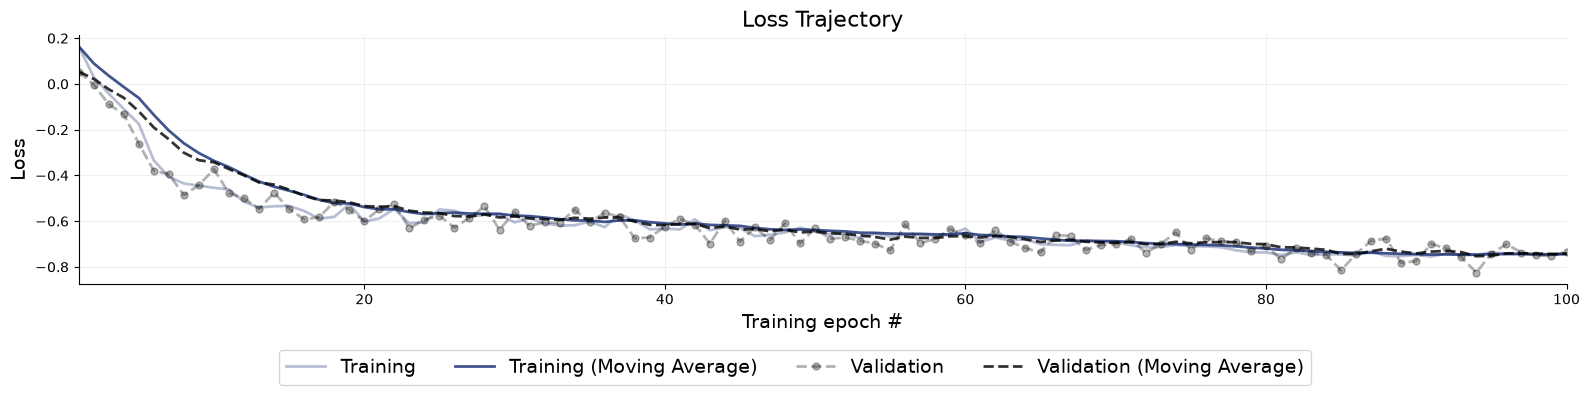

In [9]:
fig = bf.diagnostics.loss(history)

## Change the prior without retraining

Suppose new information favors smaller pulses and later arrival times, which we can express with the new priors:

$$
\frac{A-0.5}{1.5} \sim \operatorname{Beta}(2,5),
\qquad
\frac{\tau-0.2}{0.6} \sim \operatorname{Beta}(5,2).
$$

Let $p_{old}(\theta)$ denote the training prior and $p_{new}(\theta)$ the new prior. Since the likelihood is unchanged, the posterior under new prior is:

$$
p_{new}(\theta \mid x) \propto p_{old}(\theta \mid x)
\frac{p_{new}(\theta)}{p_{old}(\theta)}.
$$

Thus, we can reweight draws from the trained NPE by the prior-density ratio and resample them into the equally weighted form expected by BayesFlow diagnostics. This requires the new prior to have no support outside the training prior.

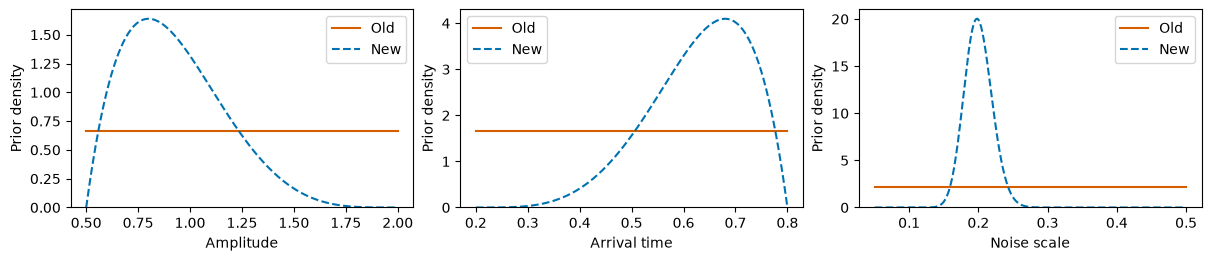

In [10]:
grid = np.linspace(0.0, 1.0, 501)
fig, axes = plt.subplots(1, 3, figsize=(12, 2.5), layout="constrained")

prior_bounds = (AMPLITUDE_BOUNDS, ARRIVAL_BOUNDS, SIGMA_BOUNDS)
plot_values = [scale_from_unit_interval(grid, bounds) for bounds in prior_bounds]

sigma_normalizer = gamma_dist.cdf(
    SIGMA_BOUNDS[1], a=NEW_SIGMA_SHAPE, scale=NEW_SIGMA_SCALE
) - gamma_dist.cdf(SIGMA_BOUNDS[0], a=NEW_SIGMA_SHAPE, scale=NEW_SIGMA_SCALE)

new_densities = (
    beta_dist.pdf(grid, 2.0, 5.0) / (AMPLITUDE_BOUNDS[1] - AMPLITUDE_BOUNDS[0]),
    beta_dist.pdf(grid, 5.0, 2.0) / (ARRIVAL_BOUNDS[1] - ARRIVAL_BOUNDS[0]),
    gamma_dist.pdf(
        plot_values[2], a=NEW_SIGMA_SHAPE, scale=NEW_SIGMA_SCALE
    ) / sigma_normalizer,
)

for ax, values, bounds, new_density, label in zip(
    axes, plot_values, prior_bounds, new_densities, LABELS
):
    width = bounds[1] - bounds[0]
    ax.plot(
        values, np.full_like(values, 1.0 / width), color="#D55E00", label="Old"
    )
    ax.plot(values, new_density, "--", color="#0072B2", label="New")
    ax.set(
        xlabel=label,
        ylabel="Prior density",
        ylim=(0, 1.05 * max(1.0 / width, new_density.max())),
    )
    ax.legend()

For a valid calibration check under the new prior, the ground-truth parameters must also be drawn from that prior. We pass their simulated data through the already-trained NPE; there is no second training call.

In [11]:
new_test = simulate_pulses(256, prior="new")

base_posterior = workflow.sample(conditions={"signal": new_test["signal"]}, num_samples=1000)

INFO:bayesflow:Sampling completed in 15.58 seconds.


The resampling utility is model-agnostic: the two callbacks below contain every model-specific detail. They accept the native BayesFlow sample dictionary and return one log density per posterior draw. The scaled Beta densities include their change-of-variables terms.

In [12]:
def old_prior_log_prob(samples):
    amplitude = samples["amplitude"][..., 0]
    arrival_time = samples["arrival_time"][..., 0]
    sigma = samples["sigma"][..., 0]

    return (
        uniform_dist.logpdf(
            amplitude,
            loc=AMPLITUDE_BOUNDS[0],
            scale=AMPLITUDE_BOUNDS[1] - AMPLITUDE_BOUNDS[0],
        )
        + uniform_dist.logpdf(
            arrival_time,
            loc=ARRIVAL_BOUNDS[0],
            scale=ARRIVAL_BOUNDS[1] - ARRIVAL_BOUNDS[0],
        )
        + uniform_dist.logpdf(
            sigma,
            loc=SIGMA_BOUNDS[0],
            scale=SIGMA_BOUNDS[1] - SIGMA_BOUNDS[0],
        )
    )


def scaled_beta_log_prob(values, bounds, shape_a, shape_b):
    width = bounds[1] - bounds[0]
    unit_values = (values - bounds[0]) / width
    return beta_dist.logpdf(unit_values, shape_a, shape_b) - np.log(width)


def new_prior_log_prob(samples):
    amplitude = samples["amplitude"][..., 0]
    arrival_time = samples["arrival_time"][..., 0]
    sigma = samples["sigma"][..., 0]
    sigma_normalizer = gamma_dist.cdf(
        SIGMA_BOUNDS[1], a=NEW_SIGMA_SHAPE, scale=NEW_SIGMA_SCALE
    ) - gamma_dist.cdf(
        SIGMA_BOUNDS[0], a=NEW_SIGMA_SHAPE, scale=NEW_SIGMA_SCALE
    )
    return (
        scaled_beta_log_prob(amplitude, AMPLITUDE_BOUNDS, 2.0, 5.0)
        + scaled_beta_log_prob(arrival_time, ARRIVAL_BOUNDS, 5.0, 2.0)
        + gamma_dist.logpdf(sigma, a=NEW_SIGMA_SHAPE, scale=NEW_SIGMA_SCALE)
        - np.log(sigma_normalizer)
    )

Before correction, the samples still describe the posterior induced by the training prior, even though these data and ground truths came from the new prior.

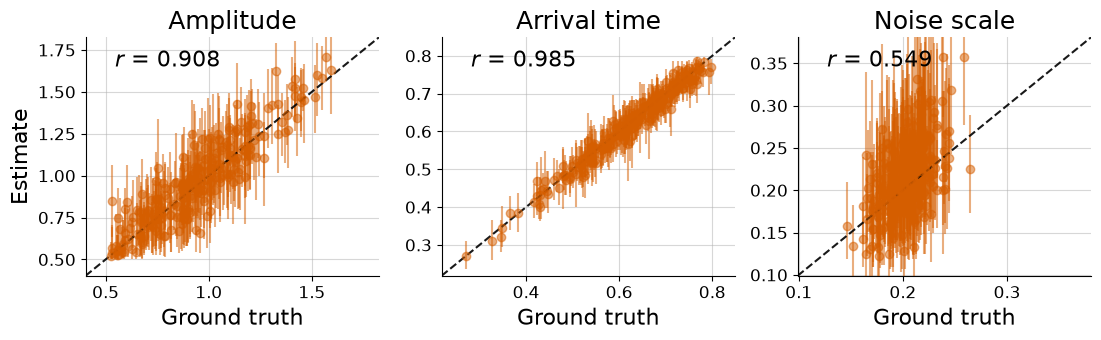

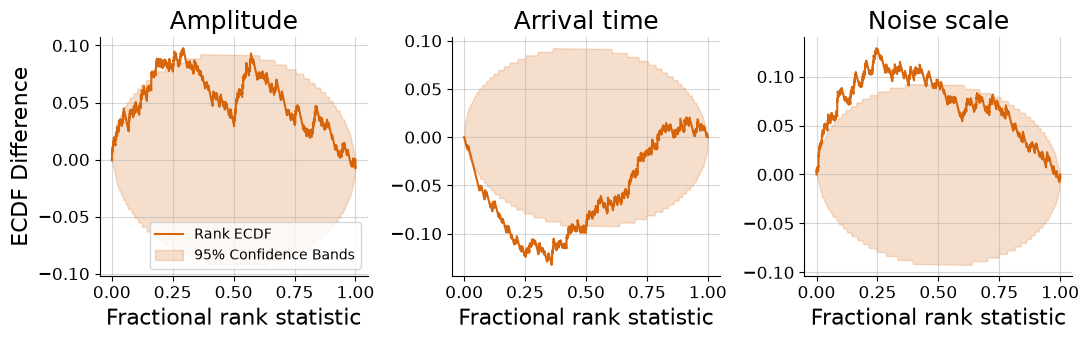

In [26]:
_ = bf.diagnostics.recovery(
    base_posterior, new_test, variable_names=LABELS, color="#D55E00", figsize=(11, 3.5)
)
_ = bf.diagnostics.calibration_ecdf(
    base_posterior,
    new_test,
    variable_names=LABELS,
    rank_ecdf_color="#D55E00",
    fill_color="#D55E00",
    legend_fontsize=10,
    figsize=(11, 3.5)
)

`importance_resample` computes the log prior-density ratio, normalizes the importance weights, and applies systematic resampling across the posterior-draw axis. The output has the same dictionary structure and array shapes as the input.

In [14]:
shifted_posterior = bf.utils.importance_resample(
    base_posterior,
    old_prior_log_prob=old_prior_log_prob,
    new_prior_log_prob=new_prior_log_prob
)

The recovery and calibration plots now assess the resampled posterior under the new prior. Calibration is mostly fixed, especially for the noise scale.

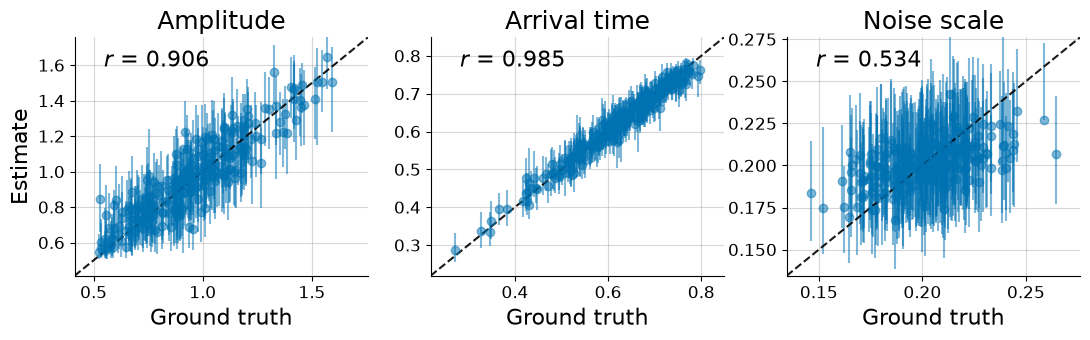

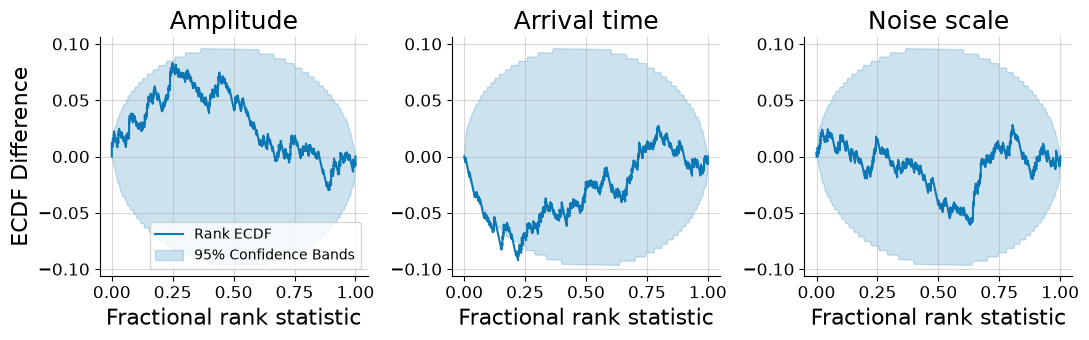

In [27]:
_ = bf.diagnostics.recovery(
    shifted_posterior, new_test, variable_names=LABELS, color="#0072B2", figsize=(11, 3.5)
)
_ = bf.diagnostics.calibration_ecdf(
    shifted_posterior,
    new_test,
    variable_names=LABELS,
    rank_ecdf_color="#0072B2",
    fill_color="#0072B2",
    figsize=(11, 3.5),
    legend_fontsize=10
)

## Limitations

Importance resampling is most useful for a contained, moderate prior change. It cannot recover posterior mass outside the training prior's support, and strongly concentrated weights leave too few distinct samples after resampling. In either case, train under a broader prior or retrain for the new prior.

Moreover, the density-ratio identity is exact for samples from the old posterior, but in SBI, the samples come from an approximation $q_\phi$. Consequently, the corrected distribution is proportional to 
$$
q_\phi(\theta \mid x) p_{new}(\theta) / p_{old}(\theta),
$$ 

and inherits any approximation error or overconfidence in the NPE ([Hermans et al., 2022](https://arxiv.org/abs/2110.06581)). Poor overlap is a separate Monte Carlo problem, as the required number of importance samples can grow roughly exponentially with the KL divergence between target and proposal ([Chatterjee & Diaconis, 2018](https://doi.org/10.1214/17-AAP1326)). Heavy right-tailed ratios lead to unstable estimates and motivate diagnostics, such as Pareto $\hat{k}$ ([Vehtari et al., 2024](https://www.jmlr.org/papers/v25/19-556.html)). 

More general prior-sensitivity calculations based on the same density-ratio identity are discussed by [Sugasawa (2026)](https://doi.org/10.1080/00031305.2026.2691097).